In [1]:
import mikeio
from watobs import DHIAltimetryRepository
import matplotlib.pyplot as plt
import os
api_key = os.getenv('DHI_ALTIMETRY_API_KEY')

In [2]:
df = mikeio.open("../output/2D_2023_2025_hrly.dfsu")
area_box = [df.geometry.element_coordinates[:,0].min(),df.geometry.element_coordinates[:,1].min(),
            df.geometry.element_coordinates[:,0].max(),df.geometry.element_coordinates[:,1].max()]
area_str = f"bbox={area_box[0]},{area_box[1]},{area_box[2]},{area_box[3]}"


start = "2023-01-01"
end = "2026-01-01"

In [3]:
# Set up altimetry repository
repo = DHIAltimetryRepository(api_key=api_key)
repo.get_satellites()

,long_name
short_name,
gs,Geosat
e1,ERS-1
tx,TOPEX
pn,Poseidon
e2,ERS-2
g1,GFO
j1,Jason-1
n1,Envisat
j2,Jason-2


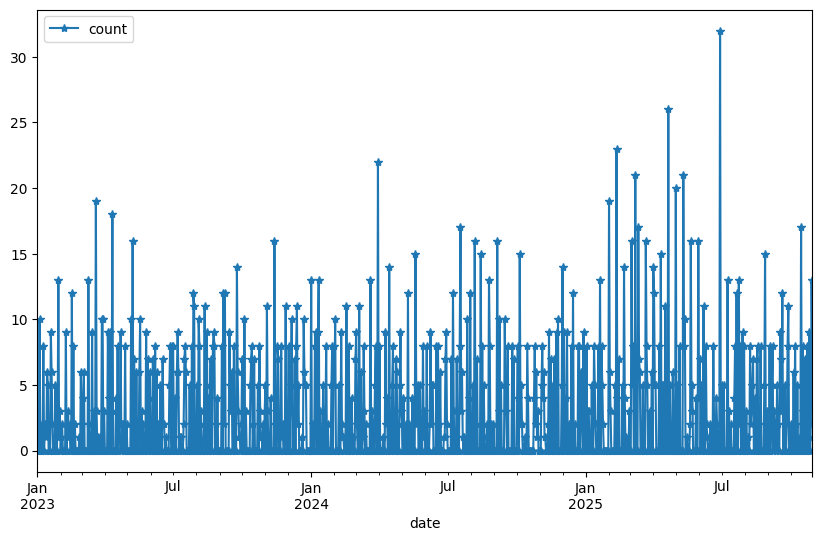

In [4]:
# Look at availability in the area and time period of interest
df = repo.get_daily_count(area=area_str, start_time=start,end_time=end)
df.plot(marker="*", figsize=(10,6));

In [5]:
# Download the data
data = repo.get_altimetry_data(area=area_str, start_time=start,end_time=end)
data.df

Succesfully retrieved 2934 records from API in 1.47 seconds


,longitude,latitude,water_level,significant_wave_height,wind_speed,distance_from_land,water_depth,satellite,quality,absolute_dynamic_topography,water_level_rms,significant_wave_height_raw,significant_wave_height_rms,wind_speed_raw,wind_speed_rads,quality_swh,quality_water_level,quality_wind_speed
datetime,,,,,,,,,,,,,,,,,,
2023-01-01 10:55:40.000,12.663183,55.285701,-0.026,NaN,NaN,13044.0,-20.93,6a,1,0.068,0.072,0.850,0.464,6.831,12.31,1,1,2
2023-01-01 10:55:41.000,12.725405,55.323157,-0.009,NaN,NaN,7357.0,-9.00,6a,1,0.079,0.037,0.766,0.542,4.516,9.09,1,1,2
2023-01-03 10:37:35.145,12.617923,56.087258,NaN,5.644,0.914,1918.0,-27.17,j3,2,NaN,0.834,5.546,4.596,0.946,0.06,2,2,2
2023-01-04 02:38:11.073,12.688781,56.009559,NaN,0.626,9.017,1284.0,-33.47,c2,2,NaN,NaN,0.539,0.547,9.016,8.08,2,2,2
2023-01-04 02:38:12.017,12.678438,55.952693,0.300,0.835,8.161,4197.0,-26.37,c2,2,0.332,0.036,0.771,0.429,8.174,7.25,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-10-30 15:46:27.000,12.563355,55.473422,0.086,0.884,3.377,9303.0,-13.88,j3,0,0.055,0.060,0.827,0.258,3.414,8.81,0,0,2
2025-10-30 15:46:28.000,12.626554,55.510891,NaN,1.193,1.803,5308.0,-10.00,j3,2,NaN,0.069,1.133,0.399,1.837,2.84,2,2,2
2025-10-30 15:46:29.000,12.689882,55.548322,NaN,9.527,1.350,4389.0,-9.00,j3,2,NaN,NaN,9.396,0.642,1.383,1.09,2,2,2


In [6]:
# Take relevant data
wl_df = data.df.loc[:,["longitude","latitude","water_level","satellite","quality_water_level"]]
wl_df.index.names = ['datetime_UTC']
wl_df

,longitude,latitude,water_level,satellite,quality_water_level
datetime_UTC,,,,,
2023-01-01 10:55:40.000,12.663183,55.285701,-0.026,6a,1
2023-01-01 10:55:41.000,12.725405,55.323157,-0.009,6a,1
2023-01-03 10:37:35.145,12.617923,56.087258,NaN,j3,2
2023-01-04 02:38:11.073,12.688781,56.009559,NaN,c2,2
2023-01-04 02:38:12.017,12.678438,55.952693,0.300,c2,2
...,...,...,...,...,...
2025-10-30 15:46:27.000,12.563355,55.473422,0.086,j3,0
2025-10-30 15:46:28.000,12.626554,55.510891,NaN,j3,2
2025-10-30 15:46:29.000,12.689882,55.548322,NaN,j3,2


In [7]:
# Filter in quality flag and distance from land (to only get water areas)
wl_df_filtered = wl_df[(data.df.loc[:,"quality_water_level"] < 2) & (data.df.loc[:,"distance_from_land"]>0.0)]
wl_df_filtered

,longitude,latitude,water_level,satellite,quality_water_level
datetime_UTC,,,,,
2023-01-01 10:55:40.000,12.663183,55.285701,-0.026,6a,1
2023-01-01 10:55:41.000,12.725405,55.323157,-0.009,6a,1
2023-01-04 02:38:13.904,12.657811,55.838957,0.265,c2,1
2023-01-04 02:38:19.564,12.596368,55.497730,0.498,c2,1
2023-01-04 02:38:20.508,12.586191,55.440855,0.515,c2,1
...,...,...,...,...,...
2025-10-29 23:33:17.983,12.639595,55.500578,0.417,c2,1
2025-10-29 23:33:18.926,12.629416,55.443658,0.446,c2,1
2025-10-29 23:33:19.870,12.619255,55.386736,0.484,c2,1


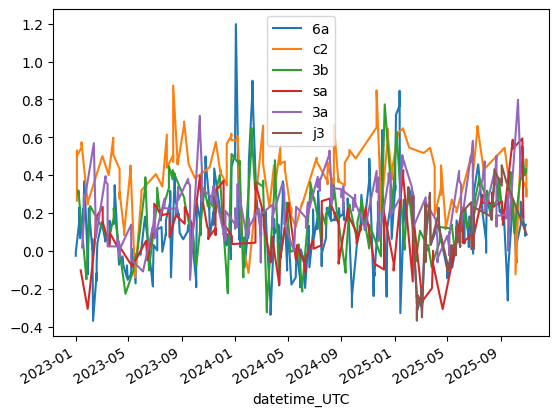

In [8]:
# Plot availability of data
for s in wl_df_filtered.satellite.unique():
    wl_df_filtered[wl_df_filtered.satellite == s].loc[:,"water_level"].plot(label=s)
plt.legend()

In [9]:
# Save data
sats=wl_df_filtered["satellite"].unique()

for sat in sats:
    df = wl_df_filtered.loc[wl_df_filtered["satellite"] == sat].drop(columns=["satellite"])
    df.to_csv(f"../observations/Altimetry_wl_{sat}.csv", date_format='%Y-%m-%dT%H:%M:%S.%f')